In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import fit_lib as fit
import BM29_lib as BM29
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False
from scipy import optimize
from scipy.optimize import curve_fit

c:\Users\riko05\Documents\8. SoSe 26\Code\BM29_data_and_analysis_2026\analysis_BM29_July2026\BM29_lib.py:421: SyntaxWarning: "\c" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\c"? A raw string is also an option.
  f"$\chi^2_{{\mathrm{{red}}}} = {red_chi2:.3f}$\n"
c:\Users\riko05\Documents\8. SoSe 26\Code\BM29_data_and_analysis_2026\analysis_BM29_July2026\BM29_lib.py:421: SyntaxWarning: "\m" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\m"? A raw string is also an option.
  f"$\chi^2_{{\mathrm{{red}}}} = {red_chi2:.3f}$\n"


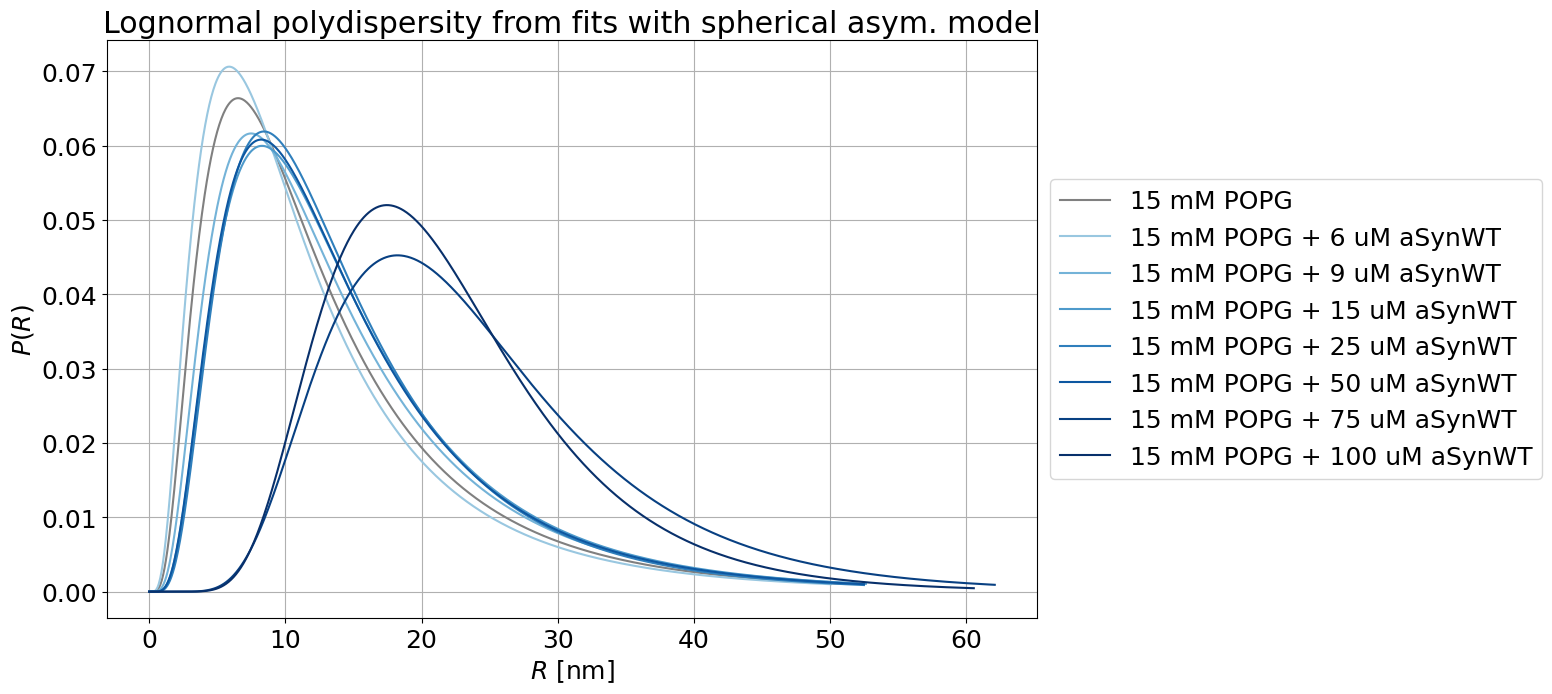

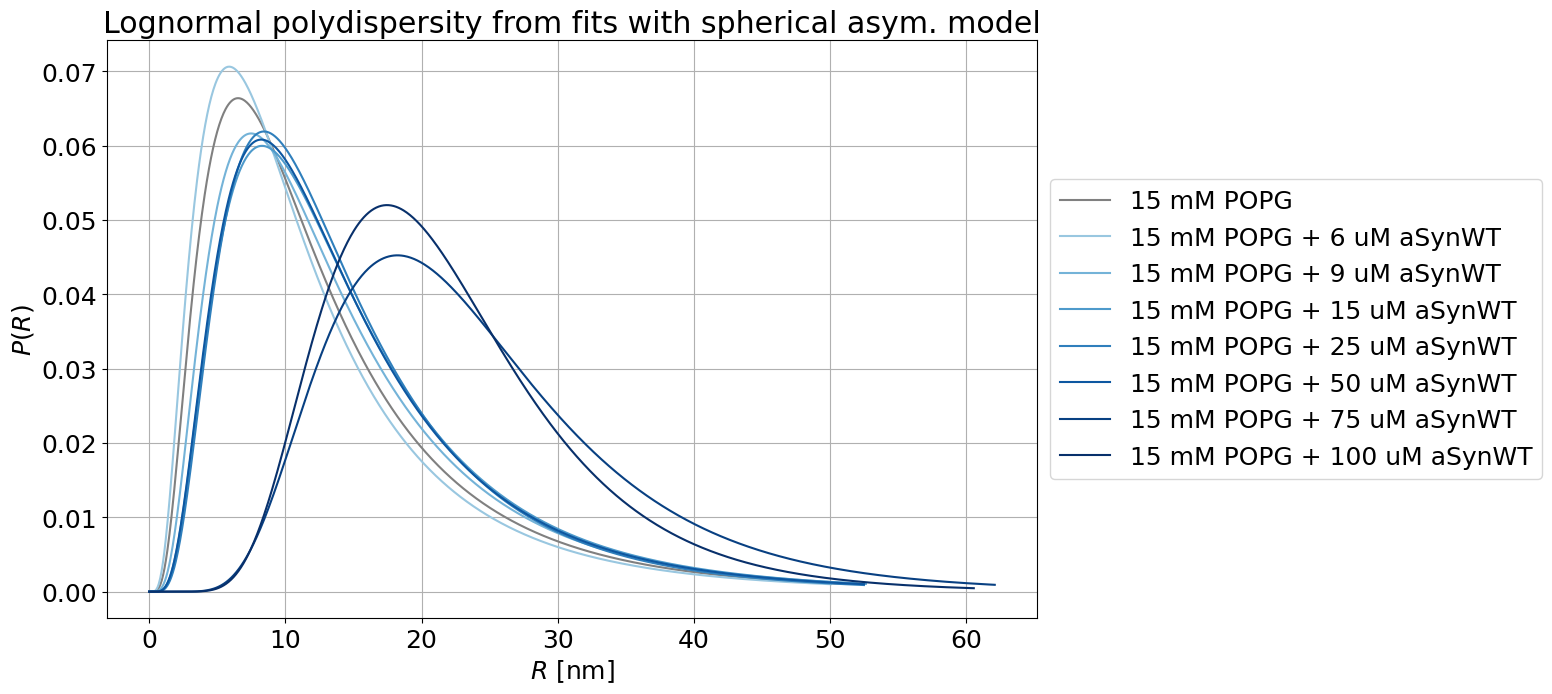

In [6]:
# PLOT LOGNORM POLYDISPERSITY FITS
who = [
    "BIX_S1",
    "BVI_S11",
    "BVI_S12",
    "BVI_S13",
    "BVI_S14",
    "BVI_S15",
    "BVI_S16",
    "BVI_S17",
    # "BVI_S18",
    # "BVI_S19",
    # "BVI_S20",
]
BM29.plot_together_lognorm_polydisp(who)

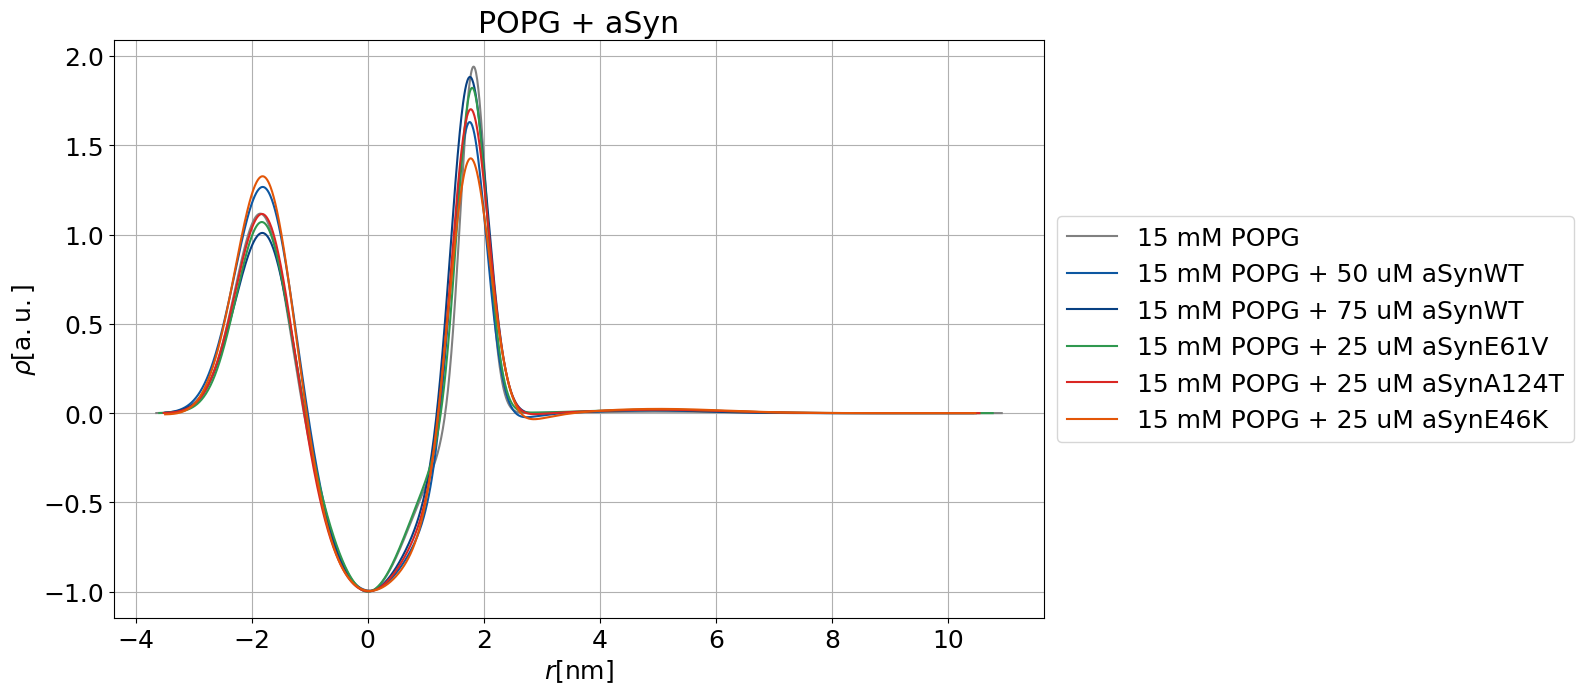

In [10]:
who = [
    "BIX_S1",
    # "BVI_S11",
    # "BVI_S12",
    # "BVI_S13",
    # "BVI_S14",
    "BVI_S15",
    "BVI_S16",
    # "BVI_S17",
    "BVI_S18",
    "BVI_S19",
    "BVI_S20",
]

BM29.plot_together(who, "POPG")
BM29.EDP_plot_together(who, "POPG + aSyn", fit_function="ULV_sph_asym_prot_layer")

In [4]:
# =============================================================================
fit_function = lambda q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale, c4: fit.ULV_spheric_asym_lognormal(q, R,    sigma_R,   rho_h1,   rho_h2,   sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,      0, 0, c4)
fit_function_name = "ULV_spheric_asym_C4_lognormal"
DAY = "Sep15"
task_name = "lognormal_BVI_S18"
# =============================================================================
p0_BVI_S14 = BM29.best_fits["BVI_S14"]["ULV_spheric_asym_C4_lognormal"][1]

who = [
    "BVI_S14",
    "BVI_S15",
]
for sample in who:
    count = 0
    
    block = sample.split("_")[0]
    block_path = BM29.blockpath(block)
    dir_names = [x.name for x in block_path.iterdir()]
    for dir_name in dir_names:
        if dir_name[:-13].endswith(sample):
            sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
            q, I, I_err_Poisson = np.loadtxt(sub_dat_path, unpack=True)

    mask = (q >= 0.07) & (q <= 5.1)
    q    = q[mask]
    I    = I[mask]
    I_err_Poisson = I_err_Poisson[mask]

    Ierr = BM29.Poisson_error_focus_minimum_highq(q, I_err_Poisson)

    thinning = 2
    q_thinned = q[::thinning]
    I_thinned = I[::thinning]
    I_err_thinned = Ierr[::thinning]
    
    # ========================== Setting Bounds ==============================
    # p0         = [   R,    sigma_R,   rho_h1,   rho_h2,    sigma_h1,  sigma_h2,  sigma_c,    z_h,   scale,   c4] 
    lower_bounds = [  13,          0,      0.8,      0.8,        0.13,      0.13,      0.5,    1.5,       0,    0] 
    upper_bounds = [   25,          1,      2.5,      2.5,         0.6,       0.6,      1.2,      2,       1,    1] 
    p0 = [13.4, 0.7451, 1.168, 1.723, 0.4556, 0.3019, 0.7631, 1.789, 4.515e-07, 0.0008046]

    print(f"Now fitting with {fit_function_name} sample {sample} ...")            
    #======================== Fit ===========================================
    try:
        popt, pcov = curve_fit(
            fit_function,
            q_thinned,
            I_thinned,
            sigma=I_err_thinned,
            maxfev=5000,
            p0=p0,
            bounds=(lower_bounds, upper_bounds)
        )
    except RuntimeError:
        print("Maximum number of evaluations reached — skipping this fit.")
        continue

    param_names = ["R_fit", "sigma_R_fit", "rho_h1_fit", "rho_h2_fit", "sigma_h1_fit", "sigma_h2_fit", "sigma_c_fit", "z_h_fit", "scale_fit", "c4_fit"]

    perr = np.sqrt(np.diag(pcov))
    fit_lib_entry = "["
    for name, value in zip(param_names, popt):
        globals()[name] = value
        fit_lib_entry += f"{value:.4g}, "
    fit_lib_entry = fit_lib_entry[:-2]
    fit_lib_entry += "]"
    print(fit_lib_entry)
    chi2, info_text_print = fit.all_info(q, I, Ierr, param_names, p0, popt, perr, fit_function, lower_bounds, upper_bounds)

    # this_file = Path(__file__).resolve()
    # analysis_BM29_July2026 = this_file.parent.parent
    # target_folder = analysis_BM29_July2026 / "Results_and_Figures" / DAY / task_name
    # if not target_folder.exists():
    #     target_folder.mkdir()

    print("Fit successful with chi2 = ", chi2)
    print(info_text_print)
    # with open(target_folder/f"info_texts_{DAY}.txt", "a", encoding="utf-8") as k:
    #     k.write(f"\n\n{BM29.sample_dict[sample]} fitted using {fit_function_name} with chi2 = {chi2}\n" + fit_lib_entry + "\n###########################################\n")

    #=========================== Plot ===========================================
    q_fit = np.linspace(min(q), max(q), 1000)
    plt.close("all")
    plt.figure(figsize=(12, 7.5))
    plt.errorbar(q, I, Ierr, marker="o", markersize=3,markeredgewidth=1,ecolor="Blue",      markeredgecolor='Blue',      markerfacecolor='None', alpha=0.5, ls="None", label='I_SUB', zorder=1)
    plt.loglog(q_fit, fit_function(q_fit, *popt), color='red', label='Fit')
    plt.loglog(q_fit, fit_function(q_fit, *p0), color='orange', label='initial guess')
    plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, 0, 0, c4_fit), color='black', label='pow law bgr')
    plt.loglog(q_fit, fit.powerlaw_bgr(q_fit, 0, 0, p0[-1]), color='black', label='initial bgr', ls="--")

    plt.xlabel('$q [1/\\mathrm{nm}]$')
    plt.ylabel('$I(q) [\\mathrm{cm}^{-1}]$')
    plt.title(f'{BM29.sample_dict[sample]} \nusing {fit_function_name}')
    plt.grid(True)
    legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')
    legend.set_title(info_text_print)
    plt.tight_layout()
    # plt.savefig(target_folder / f"{sample}_{fit_function_name}_{count}_{DAY}.png",dpi=200, bbox_inches='tight', pad_inches=0.05)

    [13, 0.6433, 1.166, 1.762, 0.4674, 0.3042, 0.7792, 1.783, 3.195e-07, 0.0008143]


Now fitting with ULV_spheric_asym_C4_lognormal sample BVI_S14 ...


Computing I(q): 100%|████████████████████████| 454/454 [00:01<00:00, 443.77it/s]


KeyboardInterrupt: 